# K-Means Clustering Global sur toutes les variables numériques

## Import des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')

# Configuration matplotlib
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (14, 8)

## Charger Dataset

In [2]:
# Charger les données nettoyées
X_train = pd.read_csv('Données/X_train_clean.csv')
print(f'Shape du dataset: {X_train.shape}')
print(f'\nPremières lignes:')
print(X_train.head(3))

Shape du dataset: (444, 34)

Premières lignes:
   Family_Size  PPI_Intersection  PPI_Union  PPI_Jaccard  Pfam_Inter  \
0            4               1.0        9.0    11.111111         1.0   
1            4               1.0       14.0     7.142857         1.0   
2            2              12.0       32.0    37.500000         1.0   

   Pfam_Union  Pfam_Jaccard      Ks      Ka     Ka_Ks  ...  \
0         1.0           1.0  1.8192  0.4049  0.222570  ...   
1         1.0           1.0  1.9732  0.4109  0.208240  ...   
2         1.0           1.0  2.3106  0.5092  0.220376  ...   

   Expression_Data_Missing  TE_Env_Pair_TE-free_TE-free  \
0                        0                         True   
1                        0                        False   
2                        0                         True   

   TE_Env_Pair_TE-free_TE-poor  TE_Env_Pair_TE-free_TE-rich  \
0                        False                        False   
1                        False                      

In [3]:
# Vérification des données
print(f'\nValeurs manquantes:\n{X_train.isnull().sum().sum()} valeurs manquantes au total')
print(f'\nTypes des colonnes:\n{X_train.dtypes.value_counts()}')


Valeurs manquantes:
0 valeurs manquantes au total

Types des colonnes:
float64    22
bool        9
int64       3
Name: count, dtype: int64


## Preprocessing

In [4]:
# Récupérer les variables numériques et les stocker dans une liste
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
X_num = X_train[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

# Standardiser les données
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_num),
    columns=X_num.columns
)

Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


## K-Means sur toutes les variables

In [5]:
# Paramètres K-means
k_values = [2, 3, 5, 10]  # Tester k = 2, 3, 5, 10
n_init = 20
random_state = 42

# Stocker les résultats pour le clustering global
kmeans_results_original = {
    'inertia': [],
    'silhouette': [],
    'davies_bouldin': [],
    'calinski_harabasz': [],
    'models': []
}

print("Exécution du K-means sur toutes les variables numériques...")
print("-" * 70)

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
    labels = kmeans.fit_predict(X_scaled)
    
    # Calculer les métriques
    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
    davies_bouldin = davies_bouldin_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
    calinski_harabasz = calinski_harabasz_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
    
    kmeans_results_original['inertia'].append(inertia)
    kmeans_results_original['silhouette'].append(silhouette)
    kmeans_results_original['davies_bouldin'].append(davies_bouldin)
    kmeans_results_original['calinski_harabasz'].append(calinski_harabasz)
    kmeans_results_original['models'].append(kmeans)
    
    print(f"✓ k={k}: Silhouette={silhouette:.4f}, Inertia={inertia:.2f}")

print("-" * 70)

Exécution du K-means sur toutes les variables numériques...
----------------------------------------------------------------------
✓ k=2: Silhouette=0.2045, Inertia=9345.06
✓ k=3: Silhouette=0.2213, Inertia=8058.21
✓ k=5: Silhouette=0.2054, Inertia=6515.86
✓ k=10: Silhouette=0.2132, Inertia=4565.73
----------------------------------------------------------------------


## Évaluation et visualisation des clusters K-means sur variables originales

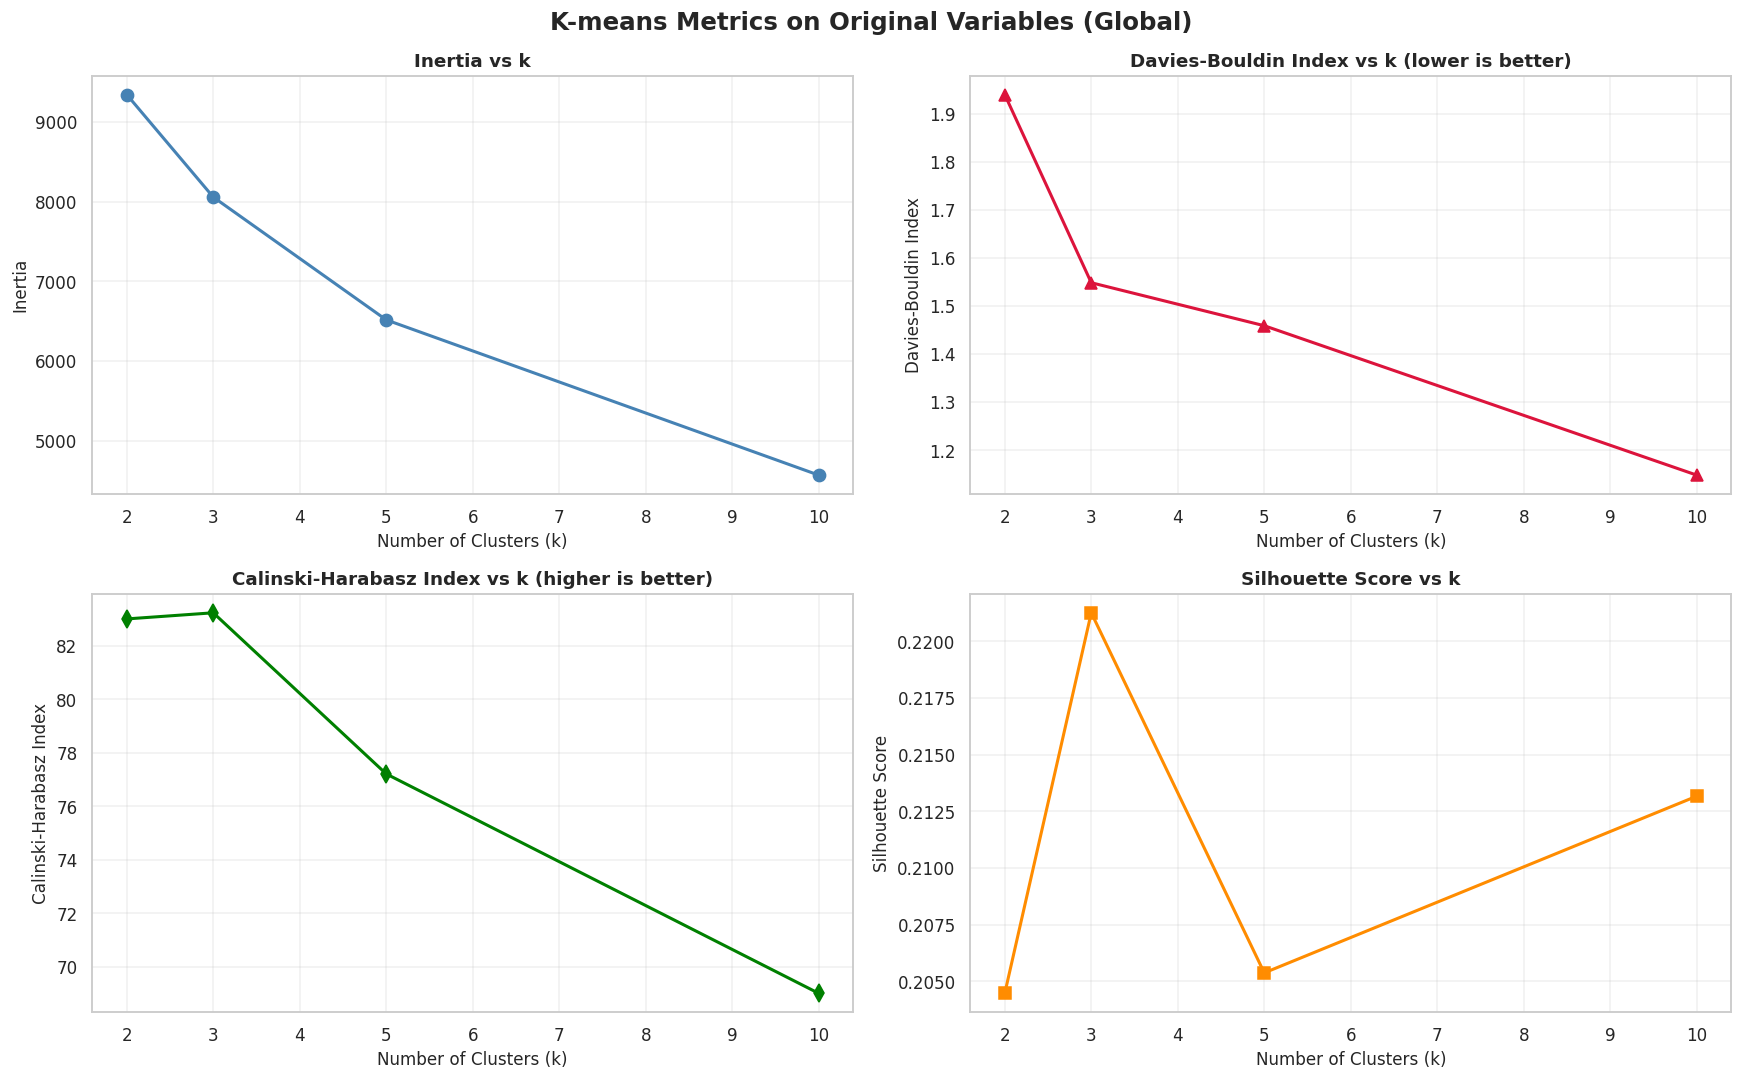


Résumé des métriques:
--------------------------------------------------------------------------------
 k Inertia Silhouette Davies-Bouldin Calinski-Harabasz
 2 9345.06     0.2045         1.9399             83.00
 3 8058.21     0.2213         1.5486             83.23
 5 6515.86     0.2054         1.4592             77.21
10 4565.73     0.2132         1.1484             69.01


In [6]:
# Visualiser les métriques
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('K-means Metrics on Original Variables (Global)', fontsize=16, fontweight='bold')

# Inertia
ax = axes[0, 0]
ax.plot(k_values, kmeans_results_original['inertia'], marker='o', linewidth=2, markersize=8, color='steelblue')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Inertia', fontsize=11)
ax.set_title('Inertia vs k', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Davies-Bouldin Index (lower is better)
ax = axes[0, 1]
ax.plot(k_values, kmeans_results_original['davies_bouldin'], marker='^', linewidth=2, markersize=8, color='crimson')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Davies-Bouldin Index', fontsize=11)
ax.set_title('Davies-Bouldin Index vs k (lower is better)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Calinski-Harabasz Index (higher is better)
ax = axes[1, 0]
ax.plot(k_values, kmeans_results_original['calinski_harabasz'], marker='d', linewidth=2, markersize=8, color='green')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Calinski-Harabasz Index', fontsize=11)
ax.set_title('Calinski-Harabasz Index vs k (higher is better)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Silhouette Score
ax = axes[1, 1]
ax.plot(k_values, kmeans_results_original['silhouette'], marker='s', linewidth=2, markersize=8, color='darkorange')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette Score vs k', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nRésumé des métriques:")
print("-" * 80)
summary_data = []
for i, k in enumerate(k_values):
    summary_data.append({
        'k': k,
        'Inertia': f"{kmeans_results_original['inertia'][i]:.2f}",
        'Silhouette': f"{kmeans_results_original['silhouette'][i]:.4f}",
        'Davies-Bouldin': f"{kmeans_results_original['davies_bouldin'][i]:.4f}",
        'Calinski-Harabasz': f"{kmeans_results_original['calinski_harabasz'][i]:.2f}"
    })
summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

## Calcul des composantes t-SNE

In [7]:
# Calculer les composantes t-SNE pour toutes les variables
print("Calcul des composantes t-SNE...")
print("-" * 70)

# Appliquer t-SNE (2 composantes)
tsne = TSNE(n_components=2, random_state=random_state, init='random', perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

tsne_results = pd.DataFrame(
    X_tsne, 
    columns=['TSNE1', 'TSNE2']
)

print(f"✓ t-SNE calculé: {X_tsne.shape} (toutes les variables → 2 composantes)")
print("-" * 70)
print(f"\nAperçu des composantes t-SNE:")
print(tsne_results.head())

Calcul des composantes t-SNE...
----------------------------------------------------------------------
✓ t-SNE calculé: (444, 2) (toutes les variables → 2 composantes)
----------------------------------------------------------------------

Aperçu des composantes t-SNE:
       TSNE1      TSNE2
0  -6.762887 -14.969991
1  21.003424   4.686025
2  -7.296627  -9.322706
3  16.730555  -4.438960
4   8.499296 -11.734517


## K-Means sur composantes t-SNE

In [8]:
# Exécuter K-means sur les composantes t-SNE
kmeans_results_tsne = {
    'inertia': [],
    'silhouette': [],
    'davies_bouldin': [],
    'calinski_harabasz': [],
    'models': [],
    'labels': {}
}

print("Exécution du K-means sur les composantes t-SNE...")
print("-" * 70)

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
    labels = kmeans.fit_predict(tsne_results.values)
    
    # Calculer les métriques
    inertia = kmeans.inertia_
    silhouette = silhouette_score(tsne_results.values, labels) if len(np.unique(labels)) > 1 else np.nan
    davies_bouldin = davies_bouldin_score(tsne_results.values, labels) if len(np.unique(labels)) > 1 else np.nan
    calinski_harabasz = calinski_harabasz_score(tsne_results.values, labels) if len(np.unique(labels)) > 1 else np.nan
    
    kmeans_results_tsne['inertia'].append(inertia)
    kmeans_results_tsne['silhouette'].append(silhouette)
    kmeans_results_tsne['davies_bouldin'].append(davies_bouldin)
    kmeans_results_tsne['calinski_harabasz'].append(calinski_harabasz)
    kmeans_results_tsne['models'].append(kmeans)
    kmeans_results_tsne['labels'][k] = labels
    
    print(f"✓ k={k}: Silhouette={silhouette:.4f}, Inertia={inertia:.2f}")

print("-" * 70)

Exécution du K-means sur les composantes t-SNE...
----------------------------------------------------------------------
✓ k=2: Silhouette=0.4988, Inertia=61941.73
✓ k=3: Silhouette=0.4527, Inertia=40816.78
✓ k=5: Silhouette=0.4251, Inertia=22883.15
✓ k=10: Silhouette=0.4243, Inertia=10089.15
----------------------------------------------------------------------


### Evaluation et Visualisation clusters K-Means sur composantes t-SNE

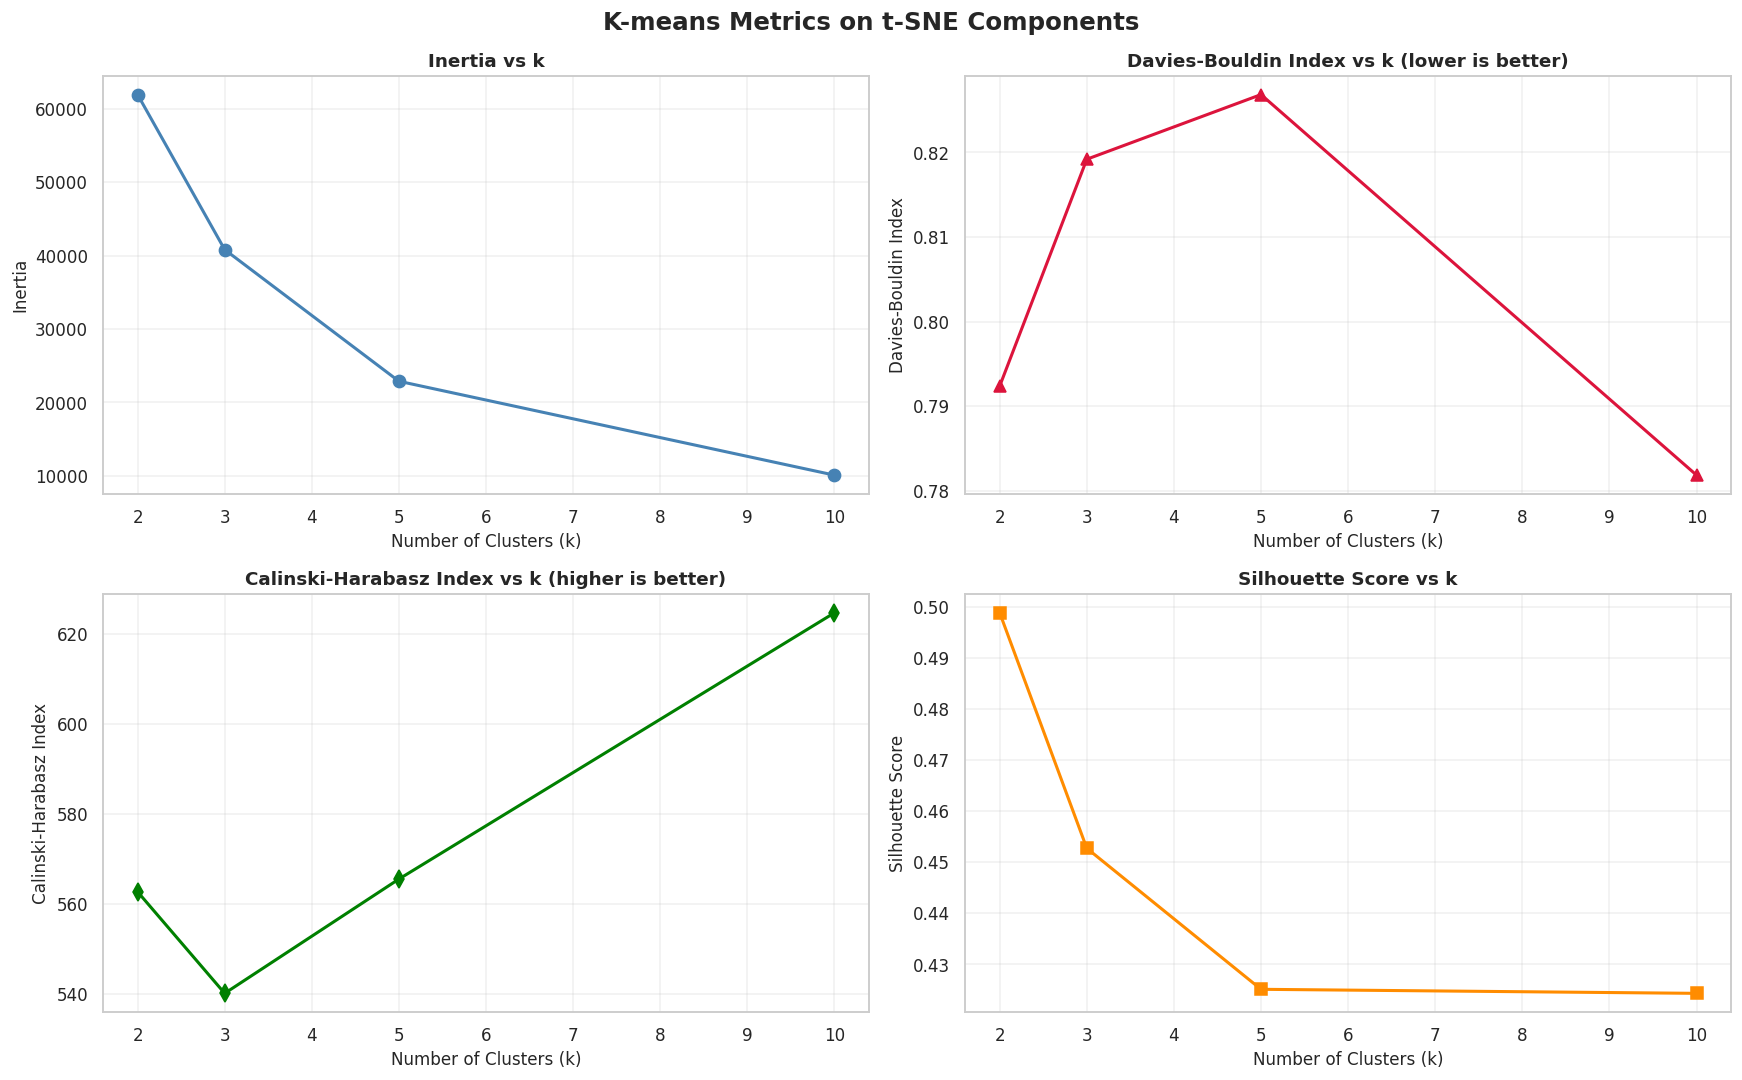


Résumé des métriques:
--------------------------------------------------------------------------------
 k  Inertia Silhouette Davies-Bouldin Calinski-Harabasz
 2 61941.73     0.4988         0.7924            562.71
 3 40816.78     0.4527         0.8192            540.13
 5 22883.15     0.4251         0.8268            565.54
10 10089.15     0.4243         0.7818            624.75


In [9]:
# Visualiser les métriques
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('K-means Metrics on t-SNE Components', fontsize=16, fontweight='bold')

# Inertia
ax = axes[0, 0]
ax.plot(k_values, kmeans_results_tsne['inertia'], marker='o', linewidth=2, markersize=8, color='steelblue')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Inertia', fontsize=11)
ax.set_title('Inertia vs k', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Davies-Bouldin Index (lower is better)
ax = axes[0, 1]
ax.plot(k_values, kmeans_results_tsne['davies_bouldin'], marker='^', linewidth=2, markersize=8, color='crimson')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Davies-Bouldin Index', fontsize=11)
ax.set_title('Davies-Bouldin Index vs k (lower is better)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Calinski-Harabasz Index (higher is better)
ax = axes[1, 0]
ax.plot(k_values, kmeans_results_tsne['calinski_harabasz'], marker='d', linewidth=2, markersize=8, color='green')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Calinski-Harabasz Index', fontsize=11)
ax.set_title('Calinski-Harabasz Index vs k (higher is better)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Silhouette Score
ax = axes[1, 1]
ax.plot(k_values, kmeans_results_tsne['silhouette'], marker='s', linewidth=2, markersize=8, color='darkorange')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette Score vs k', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nRésumé des métriques:")
print("-" * 80)
summary_data = []
for i, k in enumerate(k_values):
    summary_data.append({
        'k': k,
        'Inertia': f"{kmeans_results_tsne['inertia'][i]:.2f}",
        'Silhouette': f"{kmeans_results_tsne['silhouette'][i]:.4f}",
        'Davies-Bouldin': f"{kmeans_results_tsne['davies_bouldin'][i]:.4f}",
        'Calinski-Harabasz': f"{kmeans_results_tsne['calinski_harabasz'][i]:.2f}"
    })
summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

## Comparaison des 2 approches

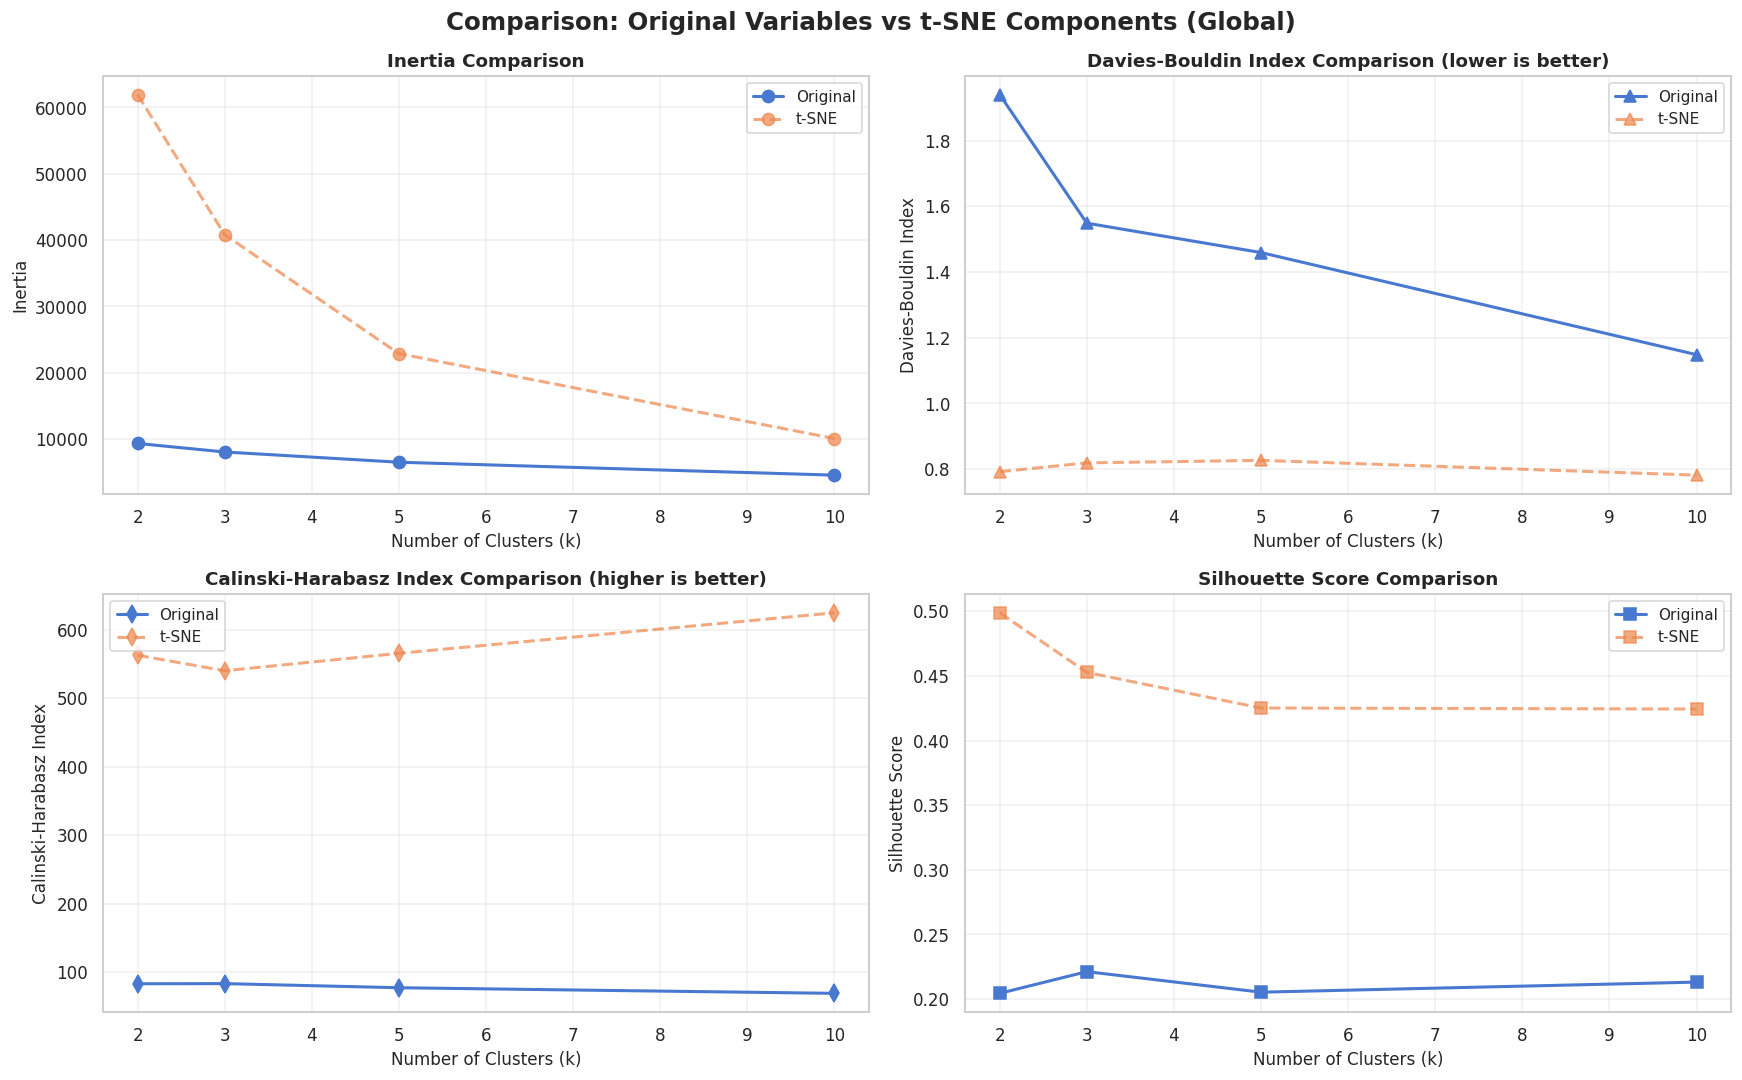

In [10]:
# Visualiser la comparaison entre les deux approches
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Comparison: Original Variables vs t-SNE Components (Global)', fontsize=16, fontweight='bold')

# Inertia comparison
ax = axes[0, 0]
ax.plot(k_values, kmeans_results_original['inertia'], marker='o', label='Original', linewidth=2, linestyle='-', markersize=8)
ax.plot(k_values, kmeans_results_tsne['inertia'], marker='o', label='t-SNE', linewidth=2, linestyle='--', markersize=8, alpha=0.7)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Inertia', fontsize=11)
ax.set_title('Inertia Comparison', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)


# Davies-Bouldin Index comparison
ax = axes[0, 1]
ax.plot(k_values, kmeans_results_original['davies_bouldin'], marker='^', label='Original', linewidth=2, linestyle='-', markersize=8)
ax.plot(k_values, kmeans_results_tsne['davies_bouldin'], marker='^', label='t-SNE', linewidth=2, linestyle='--', markersize=8, alpha=0.7)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Davies-Bouldin Index', fontsize=11)
ax.set_title('Davies-Bouldin Index Comparison (lower is better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Calinski-Harabasz Index comparison
ax = axes[1, 0]
ax.plot(k_values, kmeans_results_original['calinski_harabasz'], marker='d', label='Original', linewidth=2, linestyle='-', markersize=8)
ax.plot(k_values, kmeans_results_tsne['calinski_harabasz'], marker='d', label='t-SNE', linewidth=2, linestyle='--', markersize=8, alpha=0.7)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Calinski-Harabasz Index', fontsize=11)
ax.set_title('Calinski-Harabasz Index Comparison (higher is better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Silhouette Score comparison
ax = axes[1, 1]
ax.plot(k_values, kmeans_results_original['silhouette'], marker='s', label='Original', linewidth=2, linestyle='-', markersize=8)
ax.plot(k_values, kmeans_results_tsne['silhouette'], marker='s', label='t-SNE', linewidth=2, linestyle='--', markersize=8, alpha=0.7)
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Silhouette Score', fontsize=11)
ax.set_title('Silhouette Score Comparison', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Visualisation des clusters (k=3)

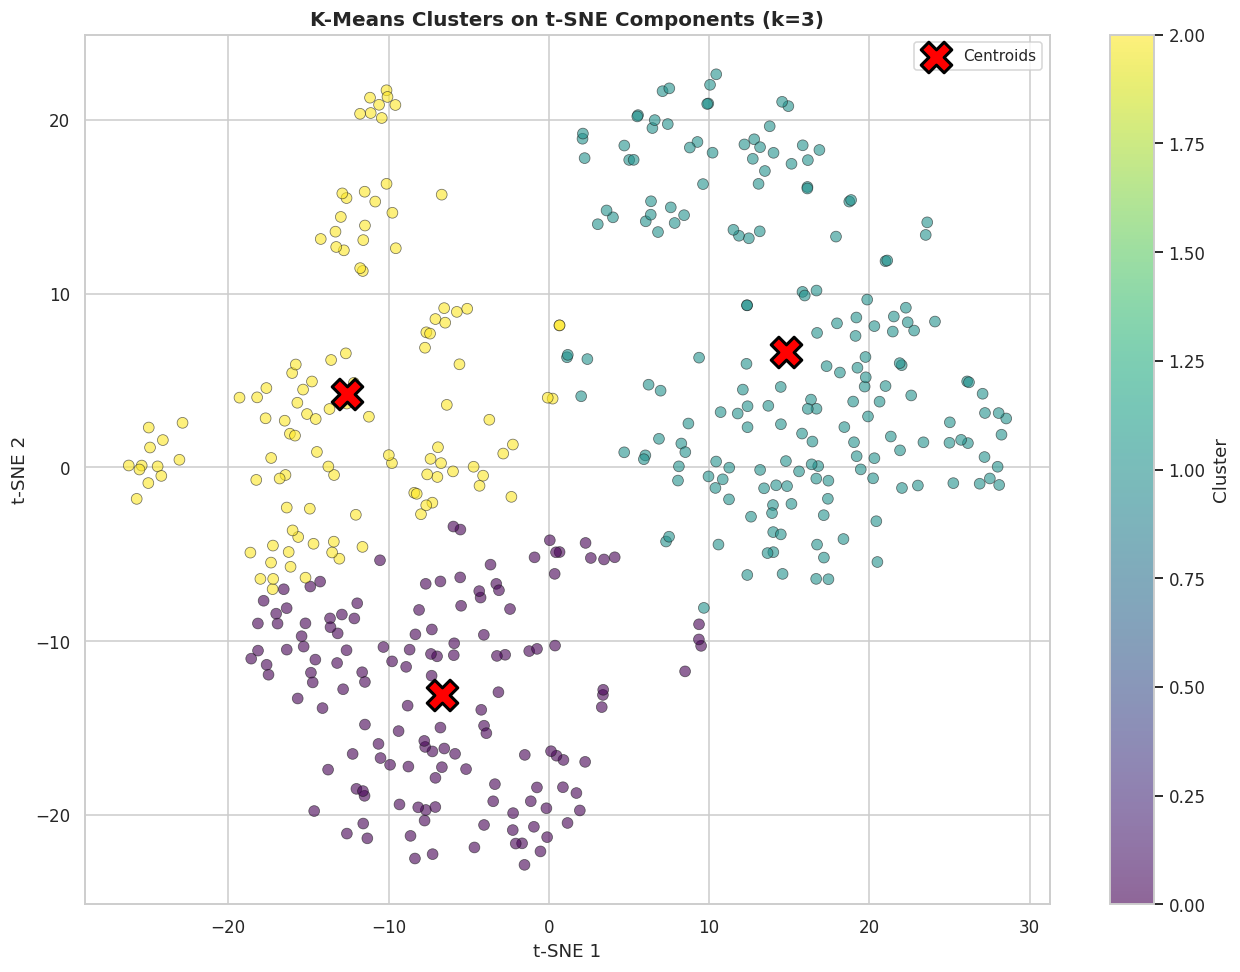

In [11]:
# Visualiser les clusters t-SNE pour k=3
k_demo = 3
labels = kmeans_results_tsne['labels'][k_demo]

fig, ax = plt.subplots(figsize=(12, 9))
scatter = ax.scatter(
    tsne_results['TSNE1'], tsne_results['TSNE2'],
    c=labels, cmap='viridis', s=50, alpha=0.6, edgecolors='k', linewidth=0.5
)

# Ajouter les centroïdes
kmeans_model = kmeans_results_tsne['models'][list(k_values).index(k_demo)]
centroids = kmeans_model.cluster_centers_
ax.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=400, 
           edgecolors='black', linewidth=2, label='Centroids')

ax.set_xlabel(f't-SNE 1', fontsize=12)
ax.set_ylabel(f't-SNE 2', fontsize=12)
ax.set_title(f'K-Means Clusters on t-SNE Components (k={k_demo})', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
plt.colorbar(scatter, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

### Tableau comparatif (k=2 vs k=3)

In [12]:
# Créer un tableau comparatif
k2_idx = 0
k3_idx = 1

print("\nComparaison des Silhouette Scores (Original vs t-SNE):")
print("=" * 100)
comparison_data = [{
    'Metric': 'Silhouette Score',
    'Original (k=2)': f"{kmeans_results_original['silhouette'][k2_idx]:.4f}",
    'Original (k=3)': f"{kmeans_results_original['silhouette'][k3_idx]:.4f}",
    't-SNE (k=2)': f"{kmeans_results_tsne['silhouette'][k2_idx]:.4f}",
    't-SNE (k=3)': f"{kmeans_results_tsne['silhouette'][k3_idx]:.4f}"
}]
comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Résumé du k optimal
print("\n\nRésumé: K optimal (selon Silhouette Score sur t-SNE):")
print("=" * 100)
silhouette_scores_tsne = kmeans_results_tsne['silhouette']
optimal_k_idx = np.argmax(silhouette_scores_tsne)
optimal_k = list(k_values)[optimal_k_idx]
max_silhouette = silhouette_scores_tsne[optimal_k_idx]

optimal_summary = pd.DataFrame([{
    'Optimal k (t-SNE)': optimal_k,
    'Max Silhouette (t-SNE)': f"{max_silhouette:.4f}",
    'Silhouette (Original, k=2)': f"{kmeans_results_original['silhouette'][0]:.4f}",
    'Silhouette (t-SNE, k=2)': f"{kmeans_results_tsne['silhouette'][0]:.4f}",
    'Silhouette (Original, optimal k)': f"{kmeans_results_original['silhouette'][optimal_k_idx]:.4f}"
}])
print(optimal_summary.to_string(index=False))


Comparaison des Silhouette Scores (Original vs t-SNE):
          Metric Original (k=2) Original (k=3) t-SNE (k=2) t-SNE (k=3)
Silhouette Score         0.2045         0.2213      0.4988      0.4527


Résumé: K optimal (selon Silhouette Score sur t-SNE):
 Optimal k (t-SNE) Max Silhouette (t-SNE) Silhouette (Original, k=2) Silhouette (t-SNE, k=2) Silhouette (Original, optimal k)
                 2                 0.4988                     0.2045                  0.4988                           0.2045


### Comparaison inertie et perplexité pour trouver k optimal

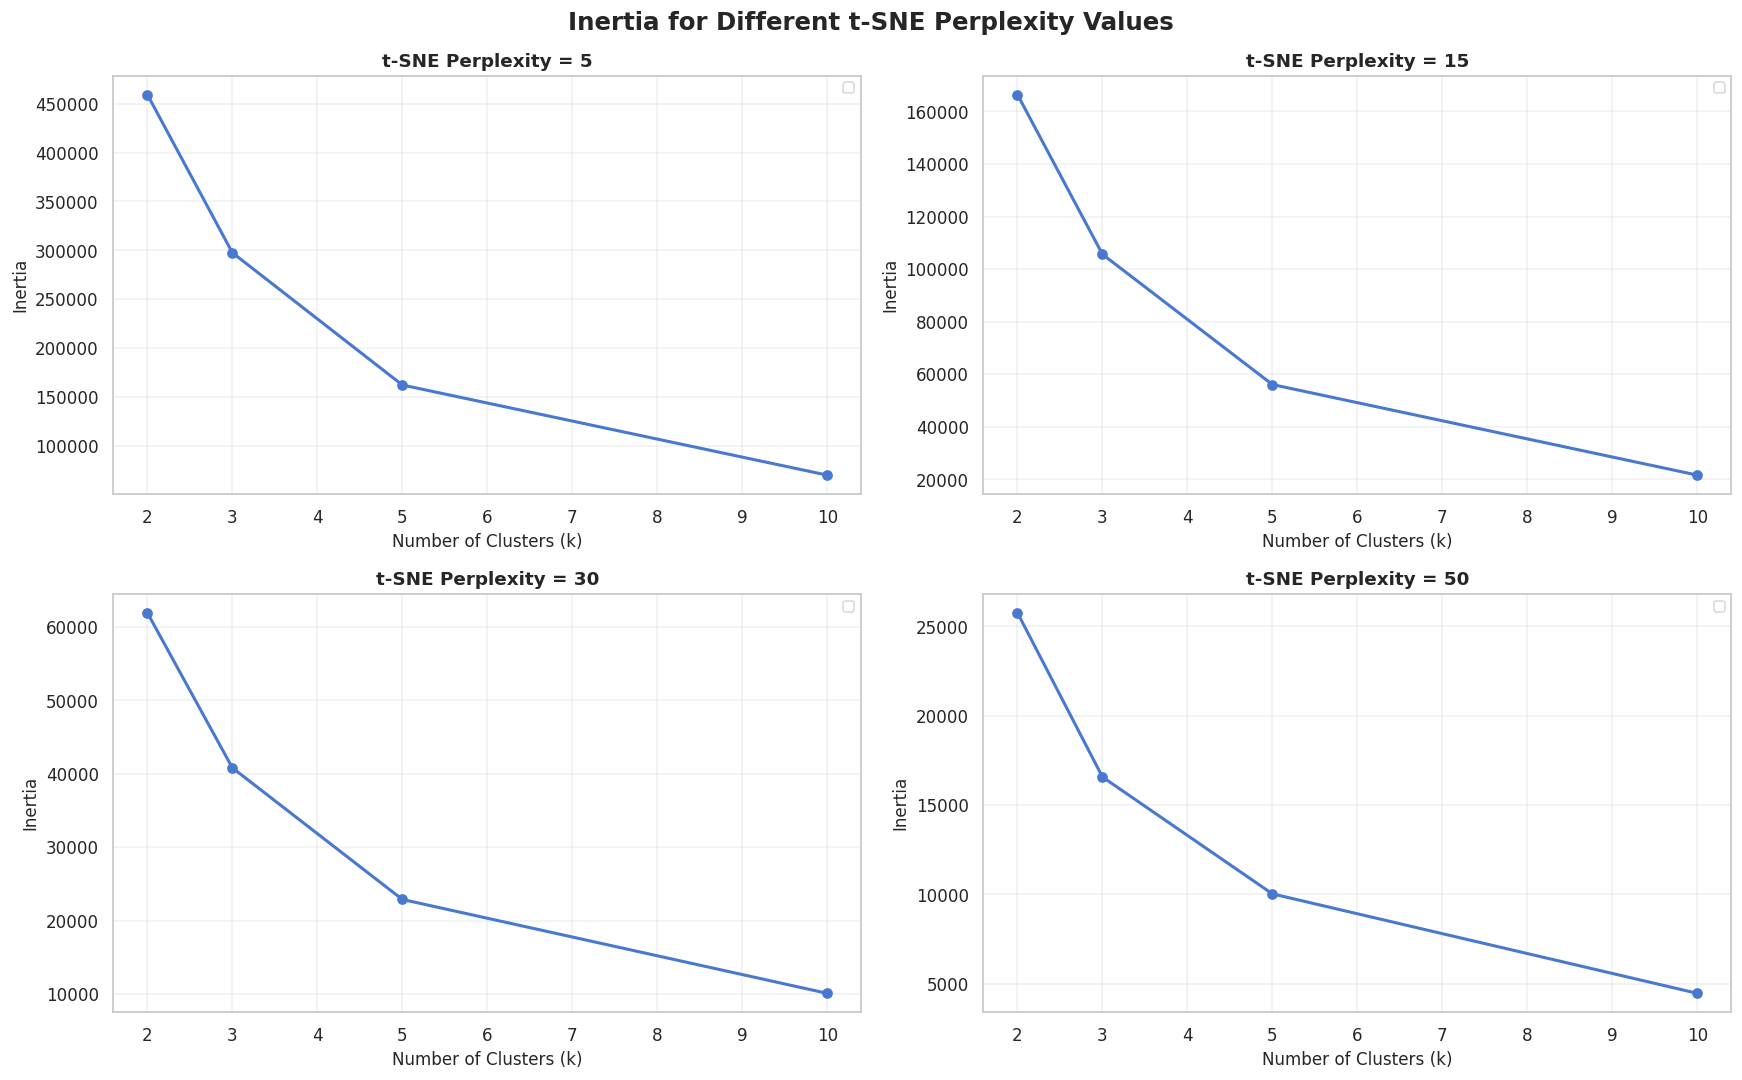

In [13]:
# Compare l'inertie pour tous les k en changeant la perplexité de t-SNE
k_values = [2, 3, 5, 10]
perplexity_values = [5, 15, 30, 50]
tsne_kmeans_results = {}
for perplexity in perplexity_values:
    tsne_kmeans_results[perplexity] = {}
    tsne = TSNE(n_components=2, random_state=random_state, init='random', perplexity=perplexity, max_iter=1000)
    X_tsne = tsne.fit_transform(X_scaled)
    
    family_results = {
        'inertia': [],
        'models': []
    }
    
    for k in k_values:
        kmeans = KMeans(n_clusters=k, n_init=n_init, random_state=random_state, init='k-means++')
        labels = kmeans.fit_predict(X_tsne)
        
        inertia = kmeans.inertia_

        family_results['inertia'].append(inertia)
        family_results['models'].append(kmeans)
    
    tsne_kmeans_results[perplexity] = family_results

# Visualiser l'inertie pour chaque perplexité
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Inertia for Different t-SNE Perplexity Values', fontsize=16, fontweight='bold')
for idx, perplexity in enumerate(perplexity_values):
    ax = axes[idx // 2, idx % 2]
    inertia_values = tsne_kmeans_results[perplexity]['inertia']
    ax.plot(k_values, inertia_values, marker='o', linewidth=2)
    ax.set_xlabel('Number of Clusters (k)', fontsize=11)
    ax.set_ylabel('Inertia', fontsize=11)
    ax.set_title(f't-SNE Perplexity = {perplexity}', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='best')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Récupération d'une matrice Z selon les clusters

In [14]:
# Récupérer la matrice Z selon les clusters en prenant le k minimisant l'inertie pour la perplexité de 50
perplexity_optimal = 50
inertia_values = tsne_kmeans_results[perplexity_optimal]['inertia']
optimal_k_idx = np.argmin(inertia_values)
optimal_k = k_values[optimal_k_idx]
print(f"K optimal pour perplexité {perplexity_optimal}: k={optimal_k} avec Inertia={inertia_values[optimal_k_idx]:.2f}")


K optimal pour perplexité 50: k=10 avec Inertia=4465.86


### Matrice Z avec t-SNE

In [23]:
# Récupérer une matrice Z selon les clusters pour perplexité de 50
perplexity_optimal = 50
k_optimal_tsne = 5

tsne = TSNE(n_components=2, random_state=random_state, init='random', perplexity=perplexity_optimal, max_iter=1000)
X_tsne_optimal = tsne.fit_transform(X_scaled)
kmeans_optimal = KMeans(n_clusters=k_optimal_tsne, n_init=n_init, random_state=random_state)
labels_optimal = kmeans_optimal.fit_predict(X_tsne_optimal)
Z_optimal = pd.DataFrame(X_tsne_optimal, columns=['TSNE1', 'TSNE2'])
Z_optimal['Cluster'] = labels_optimal
print(f"\nMatrice Z (t-SNE avec k={k_optimal_tsne} et perplexité={perplexity_optimal}):")
print(Z_optimal.head())


Matrice Z (t-SNE avec k=5 et perplexité=50):
      TSNE1     TSNE2  Cluster
0 -2.791238  2.146281        4
1  8.390980 -9.866312        3
2 -4.178054  6.712955        2
3  5.556916 -4.290371        3
4  0.491581 -3.776683        1


In [24]:
# Matrice Z de la forme (n_samples, n_clusters) avec des 1 pour indiquer l'appartenance à un cluster et 0 sinon
Z_binary = pd.get_dummies(Z_optimal['Cluster'], prefix='Cluster')
Z_binary = Z_binary.astype(int)  # Convertir en entier (0 et 1)
print(f"\nMatrice Z :")
print(Z_binary.head())


Matrice Z :
   Cluster_0  Cluster_1  Cluster_2  Cluster_3  Cluster_4
0          0          0          0          0          1
1          0          0          0          1          0
2          0          0          1          0          0
3          0          0          0          1          0
4          0          1          0          0          0


In [25]:
# Définir matrice d'adjacence binaire pour les clusters direct en utilisant la formule Z@Z.T
adjacency_matrix = Z_binary.values @ Z_binary.values.T
print(f"\nMatrice d'adjacence binaire (Z@Z.T) :")
print(f"Shape: {adjacency_matrix.shape}")

# Récupérer la somme des éléments de la matrice d'adjacence sans les éléments diagonaux 
print(f"\nNombre de paires de points dans le même cluster: {adjacency_matrix.sum() - len(adjacency_matrix)}")


Matrice d'adjacence binaire (Z@Z.T) :
Shape: (444, 444)

Nombre de paires de points dans le même cluster: 41078


### Matrice Z sans t-SNE

In [26]:
# Version où on récupère Z sans passer par t-SNE
k_optimal_sans_tsne = 3

kmeans_direct = KMeans(n_clusters=k_optimal_sans_tsne, n_init=n_init, random_state=random_state)
labels_direct = kmeans_direct.fit_predict(X_scaled)
Z_direct = pd.DataFrame(X_scaled, columns=X_scaled.columns)
Z_direct['Cluster'] = labels_direct

In [27]:
# Matrice Z de la forme (n_samples, n_clusters) avec des 1 pour indiquer l'appartenance à un cluster et 0 sinon
Z_direct_binary = pd.get_dummies(Z_direct['Cluster'], prefix='Cluster')
Z_direct_binary = Z_direct_binary.astype(int)  # Convertir en entier (0 et 1)
print(f"\nMatrice Z (K-means direct) :")
print(Z_direct_binary.head())


Matrice Z (K-means direct) :
   Cluster_0  Cluster_1  Cluster_2
0          1          0          0
1          0          1          0
2          1          0          0
3          0          1          0
4          0          1          0


In [28]:
# Définir matrice d'adjacence binaire pour les clusters direct en utilisant la formule Z@Z.T
adjacency_matrix_direct = Z_direct_binary.values @ Z_direct_binary.values.T
print(f"\nMatrice d'adjacence binaire (Z@Z.T) :")
print(f"Shape: {adjacency_matrix_direct.shape}")

# Récupérer la somme des éléments de la matrice d'adjacence sans les éléments diagonaux 
print(f"\nNombre de paires de points dans le même cluster: {adjacency_matrix_direct.sum() - len(adjacency_matrix_direct)}")


Matrice d'adjacence binaire (Z@Z.T) :
Shape: (444, 444)

Nombre de paires de points dans le même cluster: 98090


In [29]:
(444*444)/2 - 444 

98124.0